# 02 - Detector comparison

**Goal:** compare the five detectors trained on Kaggle (Optuna search, then retraining of the
best trial) with the v1 baseline, on the same comparison split, and show the champion. The
table is read from MLflow with the code that writes `docs/module1/results.md`
(`src/models/detection/compare.py`).

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR", "false")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
os.environ.setdefault("HF_HUB_DISABLE_IMPLICIT_TOKEN", "1")
ROOT = Path.cwd().resolve().parents[1]  # notebooks/<module>/ -> repository root
for path in (ROOT, ROOT / "backend"):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
os.chdir(ROOT)
warnings.filterwarnings("ignore")

import tempfile

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display
from PIL import Image

plt.rcParams.update({"figure.dpi": 72, "savefig.dpi": 72})
%config InlineBackend.figure_formats = ["jpeg"]
pd.set_option("display.max_colwidth", 90)


def fmt(frame, digits=3, **columns):
    """Format the float columns with f"{x:.{digits}f}", the rounding of the result tables."""
    out = frame.copy()
    for name in out.columns:
        if out[name].dtype.kind == "f":
            d = columns.get(name, digits)
            out[name] = out[name].map(lambda v, d=d: "" if pd.isna(v) else f"{v:.{d}f}")
    return out


def show_image(path, title="", width=480):
    """Display an image file, downscaled (the notebook stays small)."""
    import io

    from IPython.display import Image as JpegImage

    image = Image.open(path).convert("RGB")
    image.thumbnail((width, width))
    buffer = io.BytesIO()
    image.save(buffer, format="JPEG", quality=80)
    if title:
        display(Markdown(f"*{title}*"))
    display(JpegImage(data=buffer.getvalue(), format="jpeg"))

In [2]:
import mlflow

from src.utils import mlflow_utils as mu

mu.configure()  # tracking server of docker compose (http://127.0.0.1:5000), read only here
client = mlflow.MlflowClient()
TMP = Path(tempfile.mkdtemp(prefix="tujya-nb-"))  # downloaded artefacts stay outside the repo


def artefact(run_id, path):
    """Download one artefact of a run into a temporary folder and return its local path."""
    return Path(
        mlflow.artifacts.download_artifacts(run_id=run_id, artifact_path=path, dst_path=str(TMP))
    )


def champion(model):
    mv = client.get_model_version_by_alias(model, "champion")
    return mv.run_id, mv.version

## 1. Comparison table

mAP@[.5:.95] and mAP50 on the comparison split (test sessions the v1 models never saw),
precision and recall at the confidence that maximises F1, ONNX CPU latency of all models
timed together.

In [3]:
from src.models.detection import compare

rows = compare.collect()
table = pd.DataFrame([r.__dict__ for r in rows])[
    [
        "arch",
        "val_map",
        "test_map",
        "test_map50",
        "precision",
        "recall",
        "test_all_map",
        "latency_ms",
        "latency_p95_ms",
        "size_mb",
        "status",
        "version",
        "run_id",
    ]
]
table["run_id"] = table.run_id.str[:8]
display(Markdown(compare.markdown_table(rows)))  # the table of docs/module1/results.md

| Model | mAP@[.5:.95] val | mAP@[.5:.95] test | mAP50 test | Precision | Recall | mAP@[.5:.95] full v2 test | ONNX CPU mean latency (ms) | p95 (ms) | ONNX size (MB) | Parameters (M) | Version | Status | MLflow run |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|---|---|---|
| yolo11s | 0.8677 | 0.8885 | 0.9739 | 0.952 | 0.936 | 0.8722 | 63.0 | 67.1 | 37.9 | 9.5 | v9 | champion | `894871cd` |
| yolov10n | 0.8569 | 0.8860 | 0.9760 | 0.949 | 0.946 | 0.8703 | 21.9 | 23.9 | 9.4 | 2.3 | v10 | challenger | `d28c1056` |
| yolov8s | 0.8626 | 0.8830 | 0.9747 | 0.950 | 0.941 | 0.8644 | 69.7 | 73.7 | 44.7 | 11.2 | v11 | archived | `e4d25272` |
| yolov8n | 0.8563 | 0.8774 | 0.9750 | 0.947 | 0.942 | 0.8543 | 24.2 | 25.5 | 12.8 | 3.2 | v2 | archived | `b0689536` |
| fasterrcnn | 0.8063 | 0.8218 | 0.9723 | 0.951 | 0.944 | 0.8097 | 420.9 | 435.5 | 165.6 | 41.3 | v12 | archived | `96b290a7` |
| yolo11n (baseline v1) |  | 0.7888 | 0.9513 | 0.931 | 0.940 | 0.8050 | 23.8 | 25.7 | 10.7 | 2.6 | v1 | archived | `6ae2678a` |


## 2. Accuracy against latency and size

The figure of `compare.plot` (champion highlighted).

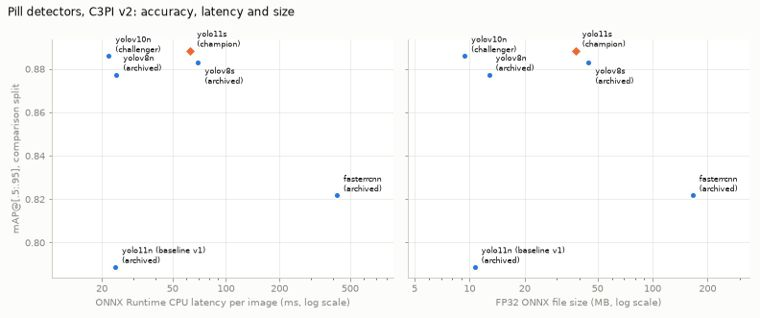

In [4]:
figure = TMP / "detectors.png"
compare.plot(rows, figure)
show_image(figure, width=760)

## 3. Champion

The Model Registry gives the alias `champion` with `promote_if_better`
(`src/models/registry.py`): a candidate must beat the champion in place by at least
`min_gain` on `test_v2_mAP50_95`.

**Champion: yolo11s** (Registry version 9, run `894871cd`): mAP@[.5:.95] 0.8885, CPU latency 63.0 ms.

*Precision-recall curve (validation)*

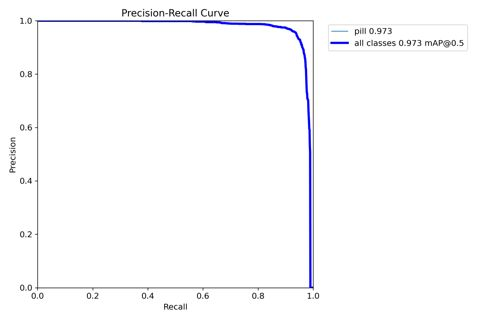

In [5]:
run_id, version = champion("tujya-pill-detector")
best = table.loc[table.run_id == run_id[:8]].iloc[0]
display(
    Markdown(
        f"**Champion: {best.arch}** (Registry version {version}, run `{run_id[:8]}`): "
        f"mAP@[.5:.95] {best.test_map:.4f}, CPU latency {best.latency_ms:.1f} ms."
    )
)
show_image(artefact(run_id, "training/BoxPR_curve.png"), "Precision-recall curve (validation)")